<a href="https://colab.research.google.com/github/Vishalkumar800/ML-projects/blob/master/housepricemodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

In [ ]:
data = pd.read_csv("housing.csv")
data_df = data.copy()

In [ ]:
TARGET_COLUMN = "median_house_value"

In [ ]:
data_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
data.shape

(20640, 10)

# EDA

`shape of data is 20640`

`in total_bedrooms columns there are 207 missing values`

```<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5

we need to handle it kyuki kuch log dominate kr rhe hai.

```



In [ ]:
data_df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
data_df.duplicated().sum()

np.int64(0)

In [ ]:
nums_columns = data_df.select_dtypes(include = [np.number]).columns.tolist()
categorical_columns = data_df.select_dtypes(include=["object"]).columns.to_list()

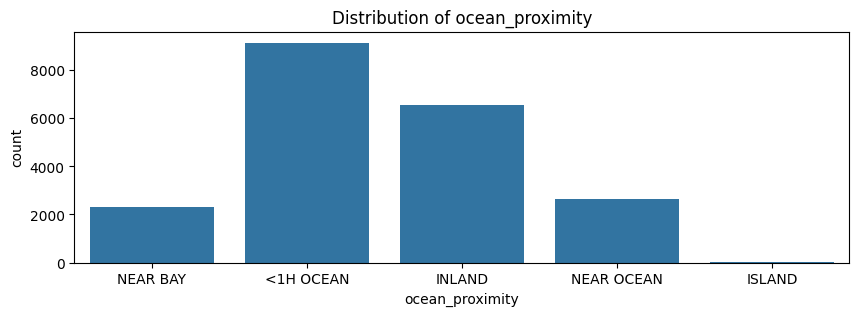

In [ ]:
for col in categorical_columns:
  plt.figure(figsize=(10,3))
  sns.countplot(data= data_df , x = col)
  plt.title(f"Distribution of {col}")
  plt.show()

In [ ]:
for col in categorical_columns:
  print(data_df[col].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


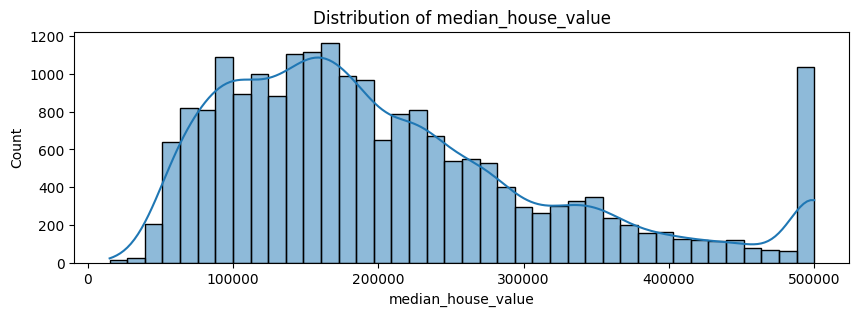

In [ ]:
# Target Column Distribution

plt.figure(figsize=(10,3))
sns.histplot(data_df[TARGET_COLUMN] , bins =  40, kde = True)
plt.title(f"Distribution of {TARGET_COLUMN}")
plt.show()

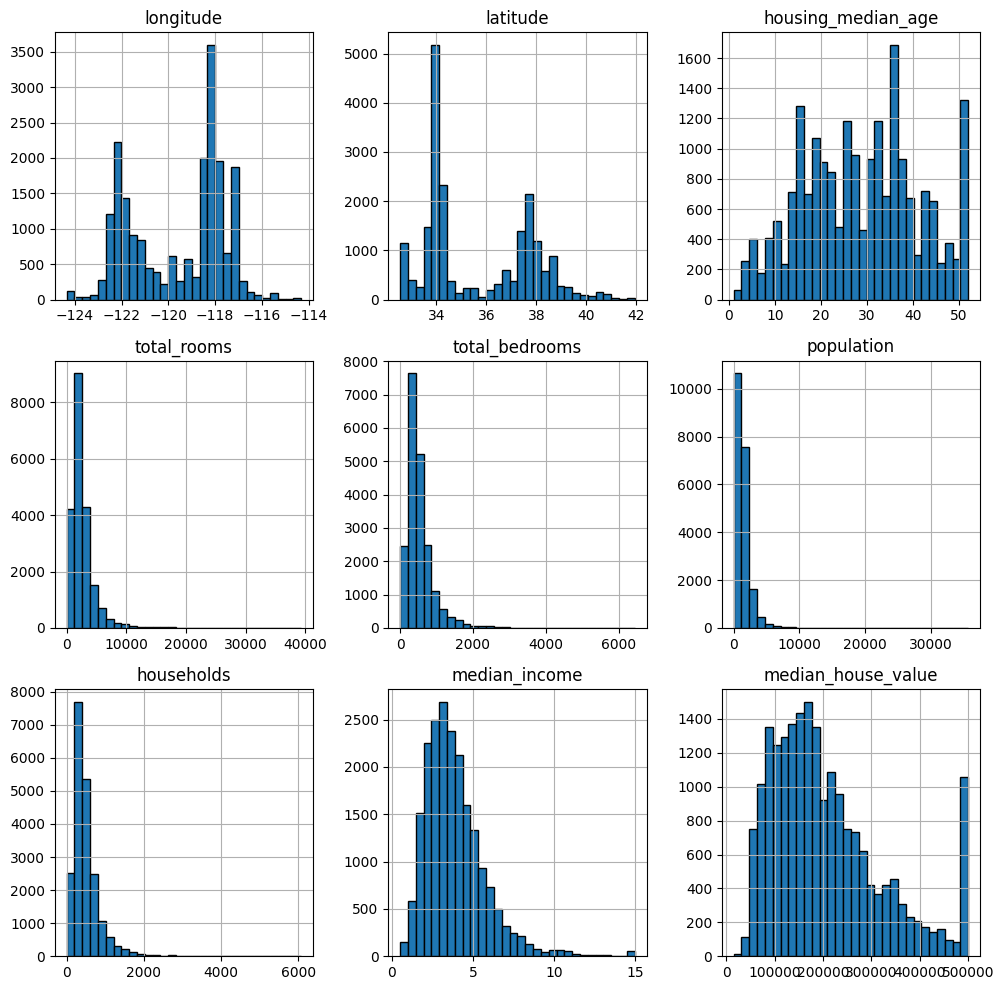

In [ ]:
from matplotlib import figure
data_df.hist(figsize = (10,10), bins = 30 ,edgecolor = "black")

plt.tight_layout()
plt.show()

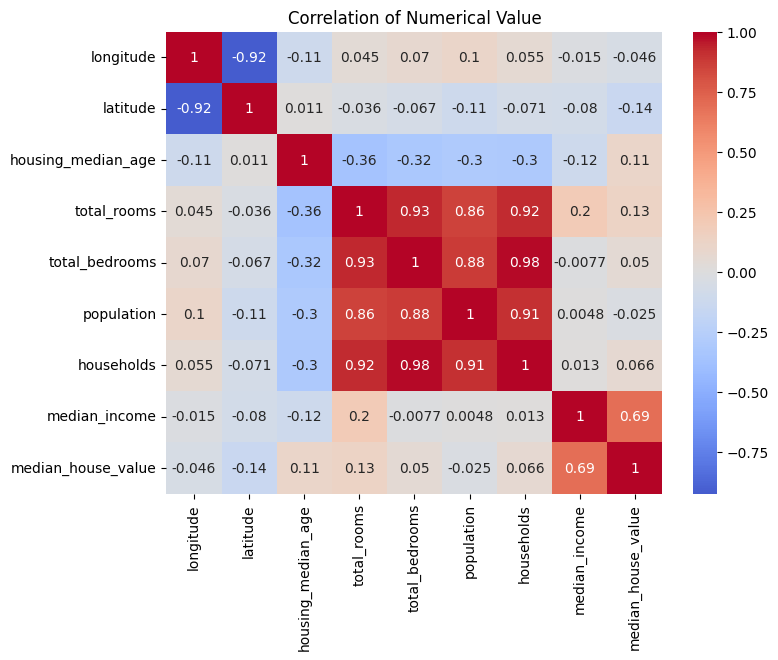

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    data_df[nums_columns].corr(),
    annot=True,
    cmap ="coolwarm",
    center = 0
)

plt.title("Correlation of Numerical Value")
plt.show()

In [ ]:
data_df[nums_columns].corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


In [ ]:
correlation_with_target = data_df[nums_columns].corr()[TARGET_COLUMN].sort_values(ascending=False)
print(correlation_with_target)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


# Data PreProcessing

In [ ]:
x =  data_df.drop(TARGET_COLUMN,axis=1)
y = data_df[TARGET_COLUMN]

In [ ]:
x_train , x_test , y_train , y_test = train_test_split(x,y , test_size=0.2, random_state=49)

In [ ]:
numerical_columns_x = x_train.select_dtypes(include= [np.number]).columns.tolist()
categorical_columns_x = x_train.select_dtypes(include=["object"]).columns.tolist()
categorical_columns_x

['ocean_proximity']